In [21]:
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse

### Baselines

In [22]:
# Baseline files
baselines = {
    "SPARSim_Ear": Path(
        "../outputs/Sparsim_Ear/"
        "sparsim_true_gene_expr_TS_Ear_2000genes_29p77pct0_110seed.h5ad"
    ),
    "SPARSim_Skin": Path(
        "../outputs/Sparsim_Skin/"
        "sparsim_true_gene_expr_TS_Skin_2000genes_19p20pct0_110seed.h5ad"
    ),
    "SymSim": Path(
        "../outputs/SymSim/"
        "symsim_true_counts_2000genes_10000cells_12p34pct0_110seed.h5ad"
    ),
    "Ear": Path(
        "../outputs/Ear/"
        "real_true_gene_expr_TS_Ear_2000genes_87p48pct0_110seed.h5ad"
    ),
    "Skin": Path(
        "../outputs/Skin/"
        "real_true_gene_expr_TM_Skin_2000genes_86p60pct0_110seed.h5ad"
    ),
    "Lung": Path(
        "../outputs/Lung/"
        "real_true_gene_expr_Other_Lung_2000genes_64p60pct0_110seed.h5ad"
    ),
    "Splat": Path(
        "../outputs/Splat/"
        "splat_true_counts_2000genes_10000cells_19p96pct0_110seed.h5ad"
    ),
}
dataset_names = list(baselines)

# Settings
target_sum = 10_000
pseudocount = 1.0

### Calculate expression and between-group variation

In [23]:
def compute_gene_stats(adata, dataset_name):
    """Per-gene mean normalized expression and between-group variance."""
    if "group" not in adata.obs.columns:
        raise KeyError(
            f"{dataset_name}: expected group labels in adata.obs['group']; "
            f"available columns: {adata.obs.columns.tolist()}"
        )

    X = adata.X.tocsr() if sparse.issparse(adata.X) else np.asarray(adata.X)

    # Per-cell total-sum scaling requires finite, nonnegative expression values
    values = X.data if sparse.issparse(X) else X
    if not np.isfinite(values).all():
        raise ValueError(f"{dataset_name}: expression matrix has non-finite values.")
    if (values < 0).any():
        raise ValueError(
            f"{dataset_name}: Per-cell total-sum scaling requires nonnegative values."
        )

    # Rescale each cell to have a total sum of target_sum
    cell_totals = np.asarray(X.sum(axis=1)).ravel()
    if (cell_totals <= 0).any():
        raise ValueError(f"{dataset_name}: found cells with zero total expression.")

    scale_factors = target_sum / cell_totals
    if sparse.issparse(X):
        X_normalized = X.multiply(scale_factors[:, None]).tocsr()
    else:
        X_normalized = X * scale_factors[:, None]

    groups = adata.obs["group"].astype(str).to_numpy()
    group_names = np.unique(groups)
    if len(group_names) < 2:
        raise ValueError(
            f"{dataset_name}: need at least two groups to calculate between-group variance."
        )

    # Calculate group mean expression (normalized)
    group_means = np.vstack([
        np.asarray(X_normalized[groups == group].mean(axis=0)).ravel()
        for group in group_names
    ])

    # Between-group variance
    log2_group_means = np.log2(group_means + pseudocount)
    signal_variance = np.var(log2_group_means, axis=0, ddof=1)

    # Mean normalized expression across all cells
    mean_expression_normalized = np.asarray(X_normalized.mean(axis=0)).ravel()

    return pd.DataFrame({
        "gene": adata.var_names,
        "mean_expression_normalized": mean_expression_normalized,
        "between_group_signal_variance": signal_variance,
        "dataset": dataset_name,
    })


results_df = pd.concat(
    [
        compute_gene_stats(ad.read_h5ad(data_path), dataset_name)
        for dataset_name, data_path in baselines.items()
    ],
    ignore_index=True,
)

# Exclude genes with zero mean expression (not shown on log-scaled axes)
is_zero = results_df["mean_expression_normalized"] == 0
print("Genes with zero mean expression removed per dataset:")
print(is_zero.groupby(results_df["dataset"], sort=False).sum().to_string())
results_df = results_df[~is_zero]

Genes with zero mean expression removed per dataset:
dataset
SPARSim_Ear     0
SPARSim_Skin    0
SymSim          0
Ear             0
Skin            0
Lung            0
Splat           0


### Distribution of mean normalized gene expression across the baseline datasets

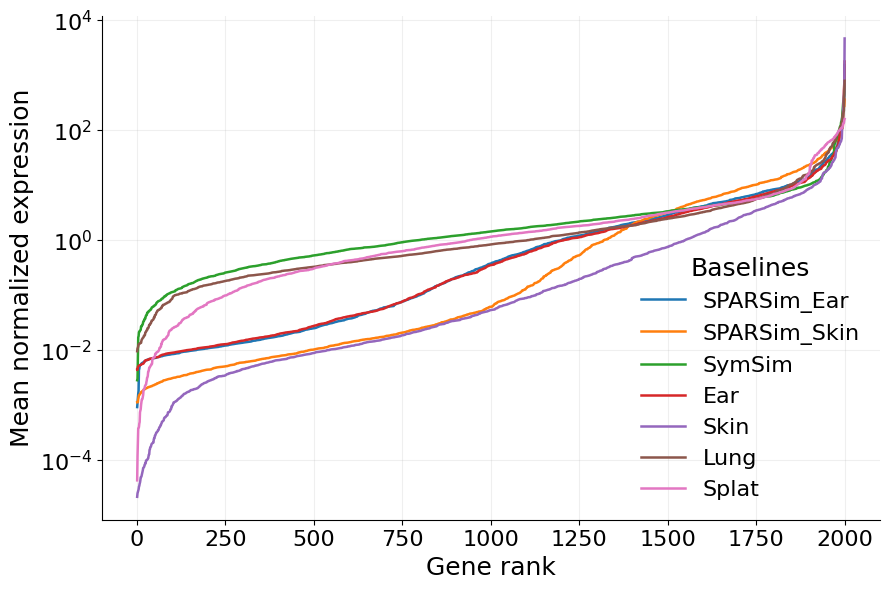

In [24]:
fig, ax = plt.subplots(figsize=(9, 6))

for dataset_name in dataset_names:
    data = (
        results_df[results_df["dataset"] == dataset_name]
        .sort_values("mean_expression_normalized")
        .reset_index(drop=True)
    )
    gene_rank = np.arange(1, len(data) + 1)

    ax.plot(
        gene_rank,
        data["mean_expression_normalized"],
        label=dataset_name,
        linewidth=1.8,
    )

ax.set_yscale("log")
ax.set_xlabel("Gene rank", fontsize=18)
ax.set_ylabel("Mean normalized expression", fontsize=18)
ax.grid(True, which="major", alpha=0.2)

# Remove the top and right sides of the plot frame
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Baselines",
    title_fontsize=18,
    fontsize=16,
    frameon=False,
)
ax.tick_params(axis="both", labelsize=16)
fig.tight_layout()
plt.show()

### Between-group variation in gene expression across baseline datasets

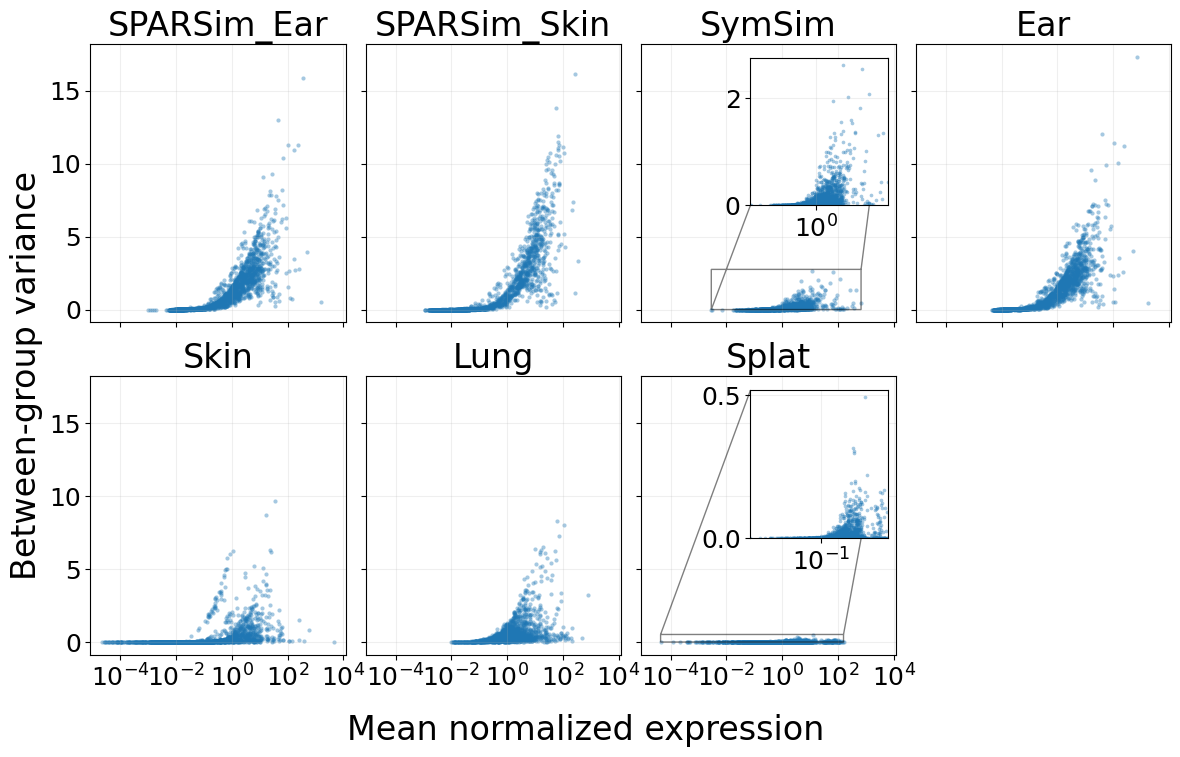

In [25]:
x_column = "mean_expression_normalized"
y_column = "between_group_signal_variance"

data_by_dataset = {
    name: results_df[results_df["dataset"] == name] for name in dataset_names
}


def plot_genes(ax, data, point_size):
    ax.scatter(
        data[x_column],
        data[y_column],
        s=point_size,
        alpha=0.4,
        color="#1F77B4",
        linewidths=0,
        rasterized=True,
    )
    ax.set_xscale("log")
    ax.grid(True, which="major", alpha=0.2)


def add_zoom_inset(ax, data):
    inset = ax.inset_axes([0.43, 0.42, 0.54, 0.53])
    plot_genes(inset, data, point_size=7)
    inset.set_xlim(data[x_column].min(), data[x_column].max())

    ymax = data[y_column].max()
    inset.set_ylim(0, ymax * 1.05 if ymax > 0 else 1)
    inset.tick_params(labelsize=18)
    ax.indicate_inset_zoom(inset, edgecolor="black")
    return inset


ncols = 4
nrows = int(np.ceil(len(dataset_names) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(12, 3.8 * nrows),
    sharex=True,
    sharey=True,
)
axes = np.asarray(axes).ravel()

for ax, dataset_name in zip(axes, dataset_names):
    data = data_by_dataset[dataset_name]
    plot_genes(ax, data, point_size=9)
    ax.tick_params(axis="both", labelsize=18)
    ax.set_title(dataset_name, fontsize=24)

# Add zoomed insets
for dataset_name in ("Splat", "SymSim"):
    if dataset_name in dataset_names:
        ax = axes[dataset_names.index(dataset_name)]
        add_zoom_inset(ax, data_by_dataset[dataset_name])

# Hide unused panels
for ax in axes[len(dataset_names):]:
    ax.set_visible(False)

fig.supxlabel("Mean normalized expression", fontsize=24)
fig.supylabel("Between-group variance", fontsize=24)
fig.tight_layout()
plt.show()